# Co-optimization and Price Formation

This notebook combines the previous notebooks and reproduces results and methodology. 

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')
# %cd /content/drive/MyDrive/Compute/
# !pip -q install cvxpy highspy

import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, cvxpy as cp, scipy.sparse as sp
# plt.rcParams.update({'font.family': 'serif', 'font.size': 8, 'savefig.dpi': 300})

### Preliminaries

We begin with preliminaries, which loads the inputs from the previous notebooks. 

We start by loading the site data, which encompasses requests, classes, headroom, and the resy of the parameters. The quantities correspond to the definitions in the demand profiling notebook. 

In [2]:
REQ   = pd.read_csv('request_coefficients.csv', index_col=0)
MODES = pd.read_csv('modes.csv', index_col=0)
PAR   = json.load(open('demand_params.json'))
D_REQ = np.load('demand_req_s.npy')              # req/s [region, class, hour]

CLASSES = list(REQ.index)
R, K, T = D_REQ.shape                            # regions, classes, hours
TAU = 3600                                       # seconds per interval

N_IN, N_OUT = REQ.n_in.values, REQ.n_out.values  # tokens per request
THETA_PRE, E_PRE = PAR['THETA_PRE'], PAR['E_PRE']
PI0_MW  = PAR['PI0_KW'] / 1e3                    # idle power per GPU
RHO     = np.array([PAR['RHO'][c] for c in CLASSES])
L_ITL   = PAR['L_ITL']                           # ms, p95 inter-token latency target
G_SITE  = np.array(PAR['G_SITE'], dtype=float)
PUE     = np.array(PAR['PUE'])
SITE_MW = np.array(PAR['SITE_MW'])
S = len(G_SITE)

We also downloaded the verified grid system. 

In [3]:
GRID = np.load('ieee30_grid.npz')
H, Cg, RATE, Dgrid = GRID['H'], GRID['Cg'], GRID['RATE'], GRID['Dgrid']
pmin, wid, slope = GRID['pmin'], GRID['wid'], GRID['slope']
BUS_I, SITE_BUS = list(GRID['BUS_I']), list(GRID['SITE_BUS'])
F_BUS, T_BUS, GEN_BUS = GRID['F_BUS'], GRID['T_BUS'], GRID['GEN_BUS']
nl, nb, ng, NSEG = H.shape[0], H.shape[1], Cg.shape[1], wid.shape[1]

We map each data-center site to its grid bus. We also set the value of lost load (VOLL). In severe grid events, the remaining generation or transmission may not cover all load. Allowing other customers' load to be shed at the VOLL keeps the problem feasible in these cases.

In [4]:
SBUS = np.array([BUS_I.index(b) for b in SITE_BUS])   # site -> bus row
Cs = np.zeros((nb, S)); Cs[SBUS, np.arange(S)] = 1    # site -> bus map
VOLL = 50_000.                                        # $/MWh, assumption

We define the network round-trip times (RTTs) between regions and sites and the RTT budget of each class. The RTT approximates network latency only, separate from queueing and token generation. Time-sensitive classes can be served only at nearby sites, while others can be routed to other sites during a supply shortage or demand surge. The RTTs are illustrative and do not represent distances on the 30-bus network.

In [5]:
RTT = np.array([[.01, .06, .12],                      # s, round trip from region to site
                [.06, .01, .06],
                [.12, .06, .01]])
RTT_MAX = {'conversation': .05, 'agentic': .10, 'offline': np.inf}   # s

The visual representation of the RTT constraints can be found below. 

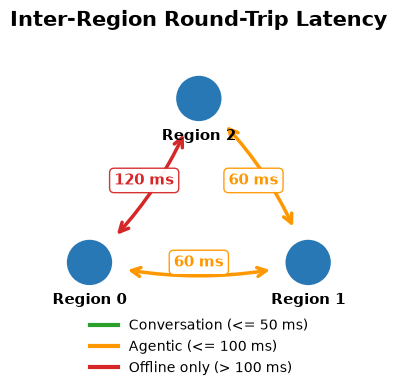

In [6]:
from matplotlib.patches import Circle, FancyArrowPatch


# regions = ["Region 1", "Region 2", "Region 3"]

regions = [f"Region {r}" for r in range(3)]

# Circular node positions
positions = {
    0: (-1, 0),
    1: (1, 0),
    2: (0, 1.5)
}

fig, ax = plt.subplots(figsize=(6, 4))

# Draw bidirectional connections
for i in range(3):
    for j in range(i + 1, 3):
        x1, y1 = positions[i]
        x2, y2 = positions[j]

        rtt = RTT[i, j]

        # Color based on latency
        color = (
            "#2ca02c" if rtt <= RTT_MAX['conversation']
            else "#ff9800" if rtt <= RTT_MAX['agentic']
            else "#d62728"
        )

        # Bidirectional arrow
        arrow = FancyArrowPatch(
            (x1, y1), (x2, y2),
            arrowstyle="<->",
            mutation_scale=16,
            linewidth=2.5,
            color=color,
            shrinkA=28,
            shrinkB=28,
            connectionstyle="arc3,rad=0.12"
        )
        ax.add_patch(arrow)

        # RTT annotation
        mx = (x1 + x2) / 2
        my = (y1 + y2) / 2

        ax.text(
            mx, my,
            f"{rtt * 1000:.0f} ms",
            ha="center", va="center",
            fontsize=11, fontweight="bold",
            color=color,
            bbox=dict(
                facecolor="white",
                edgecolor=color,
                boxstyle="round,pad=0.3",
                alpha=0.95
            )
        )

# Draw circular region nodes
for i, (x, y) in positions.items():
    circle = Circle(
        (x, y), 0.22,
        facecolor="#2878B5",
        edgecolor="white",
        linewidth=2,
        zorder=3
    )
    ax.add_patch(circle)

    ax.text(
        x, y - 0.38,
        regions[i],
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Legend
legend = [
    ("Conversation (<= 50 ms)", "#2ca02c"),
    ("Agentic (<= 100 ms)", "#ff9800"),
    ("Offline only (> 100 ms)", "#d62728")
]

for label, color in legend:
    ax.plot([], [], color=color, linewidth=3, label=label)

ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.12),
          ncol=1, frameon=False)

ax.set_title("Inter-Region Round-Trip Latency", fontsize=15,
             fontweight="bold", pad=5)

ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-0.8, 2.1)
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()


We define the full dataframe of all combinations regarding the energy serving implications of different types of requests across different locations. 

In [7]:
#for each region R, class K, site S, and mode M, create a dataframe of all possible combinations of these parameters
#filtering out any combinations where the mode's batch size exceeds the maximum allowed for that class
#the resulting dataframe will have columns for region, class, site, and mode
#as well as additional calculated columns for latency, round-trip time, input/output tokens per request
#energy consumption per request, and total input/output time and energy
ITEMS = pd.DataFrame([(k, r, s, m)
                      for k, c in enumerate(CLASSES) for r in range(R) for s in range(S)
                      for m in MODES.index if MODES.B[m] <= REQ.B_max[c]],
                     columns=['k', 'r', 's', 'm'])
ik, ir, is_, im = ITEMS.k.values, ITEMS.r.values, ITEMS.s.values, ITEMS.m.values
NI = len(ITEMS)

ITEMS['ell']   = MODES.ell.values[im]                 # ms
ITEMS['rtt']   = RTT[ir, is_]                         # s
ITEMS['a_in']  = N_IN[ik] / THETA_PRE                 # GPU-s per request, Eq. (2)
ITEMS['a_out'] = N_OUT[ik] / MODES.theta.values[im]
ITEMS['e_in']  = N_IN[ik] * E_PRE                     # J per request, Eq. (3)
ITEMS['e_out'] = N_OUT[ik] * MODES.e.values[im]
ITEMS['a'] = ITEMS.a_in + ITEMS.a_out
ITEMS['e'] = ITEMS.e_in + ITEMS.e_out

The dataframe looks as follows: 

In [8]:
ITEMS

,k,r,s,m,ell,rtt,a_in,a_out,e_in,e_out,a,e
0,0,0,0,0,17.021280,0.01,0.464601,0.886439,402.87804,508.607100,1.351041,911.485140
1,0,0,0,1,18.409154,0.01,0.464601,0.482643,402.87804,282.943224,0.947244,685.821264
2,0,0,0,2,23.068370,0.01,0.464601,0.280056,402.87804,163.307268,0.744657,566.185308
3,0,0,0,3,31.986712,0.01,0.464601,0.165843,402.87804,107.879000,0.630444,510.757040
4,0,0,0,4,44.493581,0.01,0.464601,0.128331,402.87804,87.650752,0.592933,490.528793
...,...,...,...,...,...,...,...,...,...,...,...,...
193,2,2,2,3,31.986712,0.01,0.464601,0.165843,402.87804,107.879000,0.630444,510.757040
194,2,2,2,4,44.493581,0.01,0.464601,0.128331,402.87804,87.650752,0.592933,490.528793
195,2,2,2,5,54.682418,0.01,0.464601,0.107410,402.87804,76.231330,0.572012,479.109370
196,2,2,2,6,77.617312,0.01,0.464601,0.093326,402.87804,69.551659,0.557928,472.429699


### Bids

We assume that users create an elastic demand curve, which consists of bids. In a sense, this represents how much users are ready to pay at most for the compute service. In practice, it could be implemented as some kind of user setting.

We base bids based on the current ballpark of prices. The lower bounds represent the prices for serving the model of choice in this work (LLama 3.1 70B), while the higher bound represents prices that are usually paid for more expensive models. We serve various sources (such as https://openrouter.ai/meta-llama/llama-3.1-70b-instruct#providers, https://www.together.ai/models/llama-3-1-70b, https://explainx.ai/models/meta-llama/llama-3.1-70b-instruct/cost) and create bounds based on empirical observations. 
[Note that at the time of developing the model, both prices were around 0.4 \$/M-token. At the time of write-up, the prices surged to around 0.7 \$/M-token.]

Based on that, we make one more assumption: the bids are identical for the input and output price. This was chosen as we observed identical prices for input and output of the Llama 3.1 70B model. In practice, the bids and settings could be separated. 

The bid prices are spaced geometrically. Each segment's quantity is its share times that hour's demand; the shares are the same in every hour.

In [9]:
P_LOW  = np.array([0.40, 0.40, 0.20])   # $/M tokens
P_HIGH = np.array([3.00, 3.00, 0.45])   # $/M tokens
EPS, NB = 1.0, 10

PRICE = np.array([np.geomspace(P_LOW[k], P_HIGH[k], NB) for k in range(K)])   # [class, segment]
buying = (PRICE / PRICE[:, :1]) ** (-EPS)                                     # share still buying
SEG_SHARE = np.hstack([buying[:, :-1] - buying[:, 1:], buying[:, -1:]])
VALUE = PRICE * (N_IN + N_OUT)[:, None] / 1e6                                 # $ per request

# Rows are ordered by (class, region, segment)
DBAR = np.zeros((K * R * NB, T))
V    = np.zeros(K * R * NB)
for k in range(K):
    for r in range(R):
        for b in range(NB):
            row = (k * R + r) * NB + b
            DBAR[row] = SEG_SHARE[k, b] * D_REQ[r, k]
            V[row]    = VALUE[k, b]


We check whether the bids do not exceeds the VOLL value. This is necessary as otherwise the compute price exceeds the possible energy price, and compute can outbid must-serve load (the rest of the load on the grid).

In [10]:
top_stop = 0
for k, c in enumerate(CLASSES):
    mwh = PUE.mean() * ITEMS[ITEMS.k == k].e.min() / 3.6e9                    # MWh per request
    stop = VALUE[k] / mwh
    top_stop = max(top_stop, stop.max())
    print(f'{c:12s} bids stop at ${stop.min():,.0f}-{stop.max():,.0f}/MWh')
print('VOLL above every compute bid:', VOLL > top_stop)

conversation bids stop at $4,266-31,993/MWh
agentic      bids stop at $4,577-34,325/MWh
offline      bids stop at $2,133-4,799/MWh
VOLL above every compute bid: True


Sparse matrices map served items to request balances, bid segments, GPU use (with headroom), busy GPUs, and energy use. `ROUTE` is a tiny cost per ms of RTT that only breaks ties between equivalent sites.

In [11]:
cols = np.arange(NI)
SERVE   = sp.csr_matrix((np.ones(NI), (ik * R + ir, cols)), shape=(K * R, NI))
SEGS    = sp.kron(sp.eye(K * R), np.ones((1, NB))).tocsr()
GPU_USE = sp.csr_matrix((ITEMS.a.values / RHO[ik], (is_, cols)), shape=(S, NI))
BUSY    = sp.csr_matrix((ITEMS.a.values, (is_, cols)), shape=(S, NI))
ENERGY  = sp.csr_matrix((ITEMS.e.values / 1e6, (is_, cols)), shape=(S, NI))   # MW per req/s

C_NET = 1e-9                                 # $ per request per ms of RTT (tie-breaker)
ROUTE = C_NET * RTT[ir, is_] * 1e3           # $ per request

All events hit DC1 (bus 8), the local site of region 1, during 14:00–20:00 UTC. We check that the peak demand hour lies inside this window.

In [12]:
DC1, REGION = 1, 1                           # region 1 is local to DC1
BUS_DC1 = SITE_BUS[DC1]
LINES_DC1 = (F_BUS == BUS_DC1) | (T_BUS == BUS_DC1)
GENS_DC1  = GEN_BUS == BUS_DC1
EVENT = np.arange(14, 20)                    # 14:00-20:00 UTC
TPK = D_REQ.sum(axis=(0, 1)).argmax()        # peak demand hour
assert TPK in EVENT, f'peak hour {TPK} is outside the event window'

`clear_market` solves the welfare maximization (Eqs. (6)–(17)) and returns quantities and duals. The event inputs scale DC1's site power, GPUs, line ratings, and generator availability during the event window. The compute price λ is in $ per request, and the LMP ν follows Eq. (18).

In [13]:
def clear_market(site1_power=1.0, gpu1=1.0, line8=1.0, gen8=1.0,
                 l_itl=L_ITL, rtt_max=RTT_MAX, hours=range(24), fix=None):
    """Clear the selected hours. Event inputs give the share of capability left at DC1.
    fix=(k, r, q) serves class k in region r at exactly q req/s, which traces the supply curve.
    Returns None if the problem is infeasible."""
    hours = np.array(list(hours)); nt = len(hours)

    # Apply the event to site, line, and generator limits
    pcap  = np.tile(SITE_MW[:, None], (1, 24)); pcap[DC1, EVENT] *= site1_power
    gpus  = np.tile(G_SITE[:, None], (1, 24));  gpus[DC1, EVENT] *= gpu1
    rate  = np.tile(RATE, (24, 1));             rate[np.ix_(EVENT, LINES_DC1)] *= line8
    avail = np.ones((24, ng));                  avail[np.ix_(EVENT, GENS_DC1)] = gen8
    pcap, gpus, rate, avail = pcap[:, hours], gpus[:, hours], rate[hours], avail[hours]
    Dg, dbar = Dgrid[hours], DBAR[:, hours].copy()

    # Eq. (5): remove items that miss the latency or round-trip target
    L_item = np.array([l_itl[c] for c in CLASSES])[ik]
    R_item = np.array([rtt_max[c] for c in CLASSES])[ik]
    blocked = np.where((ITEMS.ell.values > L_item) | (ITEMS.rtt.values > R_item))[0]

    # Supply curve only: replace one pair's bids with a fixed quantity
    fixed = np.zeros((K * R, nt))
    if fix is not None:
        k, r, q = fix
        dbar[(k * R + r) * NB:(k * R + r + 1) * NB] = 0
        fixed[k * R + r] = q

    z    = cp.Variable((NI, nt), nonneg=True)           # served requests/s
    d    = cp.Variable((K * R * NB, nt), nonneg=True)   # accepted demand
    y    = cp.Variable((S, nt), nonneg=True)            # powered-on GPUs
    g    = cp.Variable((nt, ng, NSEG), nonneg=True)     # generator cost pieces
    shed = cp.Variable((nt, nb), nonneg=True)           # unserved load, MW

    P_dc = cp.multiply(PUE[:, None], ENERGY @ z + PI0_MW * (y - BUSY @ z))   # Eq. (17)
    Pg   = avail * pmin + cp.sum(g, axis=2)
    inj  = Pg @ Cg.T - Dg + shed - (Cs @ P_dc).T                             # Eq. (6)
    flow = inj @ H.T

    request_balance = SERVE @ z == SEGS @ d + fixed     # Eq. (8)  -> lambda
    gpu_cap   = y <= gpus                               # Eq. (11) -> mu_G
    power_cap = P_dc <= pcap                            # Eq. (12) -> mu_P
    balance   = cp.sum(inj, axis=1) == 0                # Eq. (13) -> nu_ref
    line_up, line_lo = flow <= rate, -flow <= rate      # Eq. (14) -> kappa
    cons = [request_balance, d <= dbar, GPU_USE @ z <= y, gpu_cap, power_cap, # (8), (9)
            balance, line_up, line_lo, g <= wid[None] * avail[:, :, None], shed <= Dg]
    if len(blocked):
        cons.append(z[blocked] == 0)

    welfare = (TAU * cp.sum(V @ d) - TAU * cp.sum(ROUTE @ z)            # Eq. (7)
               - cp.sum(cp.multiply(g, slope[None])) - VOLL * cp.sum(shed))
    prob = cp.Problem(cp.Minimize(-welfare), cons)
    prob.solve(solver=cp.HIGHS)
    if prob.status != 'optimal':
        return None

    nu_ref = -balance.dual_value
    return dict(z=z.value, P_dc=P_dc.value, nu_ref=nu_ref,
                nu=nu_ref[:, None] - (line_up.dual_value - line_lo.dual_value) @ H,   # Eq. (18)
                lam=-request_balance.dual_value.reshape(K, R, nt) / TAU,              # $ per request
                muG=gpu_cap.dual_value, muP=power_cap.dual_value,
                served=(SERVE @ z.value).reshape(K, R, nt),
                shed=shed.value.sum(), welfare=-prob.value)

def per_Mtok(res, k, r, t):
    """Compute price in $/M tokens."""
    return res['lam'][k, r, t] / (N_IN[k] + N_OUT[k]) * 1e6

We choose the grid event as the mildest tested derating of the lines into bus 8 that raises the DC1 LMP above $500/MWh at the peak hour without shedding load. The selected setting limits these lines to 30% of their rating.

In [14]:
EVENT_LMP_MIN = 500                          # $/MWh

calib = []
for gen8 in [1.0, 0.0]:
    for line8 in [0.8, 0.6, 0.5, 0.4, 0.3, 0.2]:
        res = clear_market(line8=line8, gen8=gen8, hours=[TPK])
        calib.append(dict(gen8=gen8, line8=line8, lmp_dc1=res['nu'][0, SBUS[DC1]], shed_MW=res['shed']))
calib = pd.DataFrame(calib)
print(calib.round(2))

ok = calib[(calib.shed_MW < 1e-6) & (calib.lmp_dc1 >= EVENT_LMP_MIN)]
if ok.empty:
    raise ValueError('No tested setting reaches the target LMP without unserved load.')
GRID_EVENT = ok.iloc[0][['line8', 'gen8']].to_dict()
print('grid event:', GRID_EVENT)

C:\Users\16467\AppData\Local\Temp\ipykernel_32256\3652244664.py:52: UserWarning: The problem has an expression with dimension greater than 2. Defaulting to the SCIPY backend for canonicalization.
  prob.solve(solver=cp.HIGHS)


    gen8  line8   lmp_dc1  shed_MW
0    1.0    0.8     56.57     0.00
1    1.0    0.6     57.19     0.00
2    1.0    0.5     62.24     0.00
3    1.0    0.4     62.40     0.00
4    1.0    0.3   2413.35     0.00
5    1.0    0.2   3571.03     0.00
6    0.0    0.8  50000.00     4.21
7    0.0    0.6  50000.00    11.67
8    0.0    0.5  50000.00    15.39
9    0.0    0.4  50000.00    19.12
10   0.0    0.3  50000.00    22.85
11   0.0    0.2  50000.00    26.58
grid event: {'line8': 0.3, 'gen8': 1.0}


We clear the full day for the base case and three events: 60% of DC1's GPUs offline ("GPU failure"), DC1's site power reduced from 25 to 10 MW ("power limit"), and the grid event above. Table IV of the paper reports the peak hour.

In [15]:
EVENTS = {'base':        dict(),
          'GPU failure': dict(gpu1=0.4),
          'power limit': dict(site1_power=0.4),
          'grid event':  GRID_EVENT}
COLOR = {'base': 'C0', 'GPU failure': 'C3', 'power limit': 'C2', 'grid event': 'C1'}
RES = {name: clear_market(**kw) for name, kw in EVENTS.items()}

summary = {}
for name, res in RES.items():
    summary[name] = {'LMP DC1 ($/MWh)':     res['nu'][TPK, SBUS[DC1]],
                     'mu_G DC1 ($/GPU-h)':  res['muG'][DC1, TPK],
                     'mu_P DC1 ($/MWh)':    res['muP'][DC1, TPK],
                     'unserved load (MWh)': res['shed'],
                     **{f'{c}: price ($/M)': per_Mtok(res, k, REGION, TPK)
                        for k, c in enumerate(CLASSES)},
                     **{f'{c}: served share': res['served'][k, REGION, TPK] / D_REQ[REGION, k, TPK]
                        for k, c in enumerate(CLASSES)}}
print(f'Peak hour: {TPK}:00 UTC')
print(pd.DataFrame(summary).round(3))

C:\Users\16467\AppData\Local\Temp\ipykernel_32256\3652244664.py:52: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  prob.solve(solver=cp.HIGHS)


Peak hour: 15:00 UTC
                              base  GPU failure  power limit  grid event
LMP DC1 ($/MWh)             56.569       55.318       55.943    2413.346
mu_G DC1 ($/GPU-h)           0.007        2.802        0.000       0.000
mu_P DC1 ($/MWh)             0.000        0.000     2761.011       0.000
unserved load (MWh)          0.000        0.000        0.000       0.000
conversation: price ($/M)    0.007        0.400        0.316       0.270
agentic: price ($/M)         0.005        0.235        0.229       0.197
offline: price ($/M)         0.006        0.262        0.255       0.219
conversation: served share   1.000        0.832        1.000       1.000
agentic: served share        1.000        1.000        1.000       1.000
offline: served share        1.000        0.738        0.763       0.873


We split each compute price into the components of Table II, using the site that serves most of each class–region pair. The residual check confirms that the components sum to the dual λ (Eq. (19)).

In [16]:
COMPS = ['energy', 'congestion', 'site power', 'GPU', 'SLO headroom']

def decompose(res, t):
    rows, checks = [], []
    for k, c in enumerate(CLASSES):
        for r in range(R):
            share = res['served'][k, r, t] / D_REQ[r, k, t]
            if share < 1e-6:
                rows += [dict(cls=c, region=r, site=-1, part=part, served=share,
                              **{x: np.nan for x in COMPS}) for part in ['input', 'output']]
                continue
            mine = np.where((ik == k) & (ir == r))[0]
            i = mine[res['z'][mine, t].argmax()]
            s = is_[i]
            nu_site, nu_ref = res['nu'][t, SBUS[s]], res['nu_ref'][t]
            mu_G, mu_P = res['muG'][s, t], res['muP'][s, t]
            total = ROUTE[i]
            for part, sfx, n_tok in [('input', 'in', N_IN[k]), ('output', 'out', N_OUT[k])]:
                a  = ITEMS['a_' + sfx][i]
                MW = PUE[s] * ITEMS['e_' + sfx][i] / 1e6
                comp = {'energy':       MW * nu_ref,
                        'congestion':   MW * (nu_site - nu_ref),
                        'site power':   MW * mu_P,
                        'GPU':          a * mu_G,
                        'SLO headroom': (1 / RHO[k] - 1) * a * (mu_G + PUE[s] * PI0_MW * (nu_site + mu_P))}
                total += sum(comp.values()) / TAU
                rows.append(dict(cls=c, region=r, site=s, part=part, served=share,
                                 **{x: v / TAU / n_tok * 1e6 for x, v in comp.items()}))   # $/M tokens
            checks.append(abs(total - res['lam'][k, r, t]) / res['lam'][k, r, t])
    return pd.DataFrame(rows), checks

DECOMP, residuals = {}, []
for name, res in RES.items():
    DECOMP[name], chk = decompose(res, TPK)
    residuals += chk
print(f'largest relative residual: {max(residuals):.2e}')

largest relative residual: 3.97e-16


In [17]:


t = TPK
base = RES['base']

rows = {}
for name, res in RES.items():
    served = res['served'][:, :, t]                   # req/s [class, region]
    rows[name] = {
        'LMP at DC1 ($/MWh)':          res['nu'][t, SBUS[DC1]],
        'DC1 power (MW)':              res['P_dc'][DC1, t],
        'DC1 reduction vs base (MW)':  base['P_dc'][DC1, t] - res['P_dc'][DC1, t],
        'Fleet power (MW)':            res['P_dc'][:, t].sum(),
        **{f'Price, {c} ($/M tok)':    per_Mtok(res, k, REGION, t)
           for k, c in enumerate(CLASSES)},
        **{f'Served, {c} (%)':         100 * served[k].sum() / D_REQ[:, k, t].sum()
           for k, c in enumerate(CLASSES)},
        'Grid load shed (MWh/day)':    res['shed'],
        'Welfare loss vs base (k$/day)': (base['welfare'] - res['welfare']) / 1e3,
    }

TABLE = pd.DataFrame(rows)
print(TABLE.round(3))


                                  base  GPU failure  power limit  grid event
LMP at DC1 ($/MWh)              56.569       55.318       55.943    2413.346
DC1 power (MW)                  21.818        7.660       10.000      12.144
DC1 reduction vs base (MW)       0.000       14.158       11.818       9.674
Fleet power (MW)                55.447       50.867       53.127      55.031
Price, conversation ($/M tok)    0.007        0.400        0.316       0.270
Price, agentic ($/M tok)         0.005        0.235        0.229       0.197
Price, offline ($/M tok)         0.006        0.262        0.255       0.219
Served, conversation (%)       100.000       90.564       96.947     100.000
Served, agentic (%)            100.000      100.000      100.000     100.000
Served, offline (%)            100.000       72.263       76.314      86.218
Grid load shed (MWh/day)         0.000        0.000        0.000       0.000
Welfare loss vs base (k$/day)    0.000       75.466       34.479       5.030

In [18]:
# %% Check: where is demand curtailed, and where does power move?
t = TPK
base = RES['base']
for name, res in RES.items():
    print(f'\n=== {name} ===')
    share = 100 * res['served'][:, :, t] / D_REQ[:, :, t].T          # [class, region]
    print('Served (%) by class and region:')
    print(pd.DataFrame(share, index=CLASSES,
                       columns=[f'region {r}' for r in range(R)]).round(1))
    print('Price ($/M tokens) by class and region:')
    print(pd.DataFrame([[per_Mtok(res, k, r, t) for r in range(R)] for k in range(K)],
                       index=CLASSES, columns=[f'region {r}' for r in range(R)]).round(3))
    print('Site power (MW):     ', res['P_dc'][:, t].round(2))
    print('Change vs base (MW): ', (res['P_dc'][:, t] - base['P_dc'][:, t]).round(2))


=== base ===
Served (%) by class and region:
              region 0  region 1  region 2
conversation     100.0     100.0     100.0
agentic          100.0     100.0     100.0
offline          100.0     100.0     100.0
Price ($/M tokens) by class and region:
              region 0  region 1  region 2
conversation     0.007     0.007     0.007
agentic          0.005     0.005     0.005
offline          0.006     0.006     0.006
Site power (MW):      [20.39 21.82 13.24]
Change vs base (MW):  [0. 0. 0.]

=== GPU failure ===
Served (%) by class and region:
              region 0  region 1  region 2
conversation      91.6      83.2     100.0
agentic          100.0     100.0     100.0
offline           69.7      73.8      76.3
Price ($/M tokens) by class and region:
              region 0  region 1  region 2
conversation     0.400     0.400     0.395
agentic          0.238     0.235     0.235
offline          0.262     0.262     0.262
Site power (MW):      [20.9   7.66 22.3 ]
Change vs base (

In [19]:
# %% Check: does the price rise only when DC0 and DC2 are full?
k_off = CLASSES.index('offline')
for name in ['GPU failure', 'power limit', 'grid event']:
    res = RES[name]
    use = (GPU_USE @ res['z']) / G_SITE[:, None]       # share of installed GPUs reserved [site, hour]
    print(f'\n=== {name} ===')
    print(pd.DataFrame({
        'offline price ($/M)': [per_Mtok(res, k_off, REGION, t) for t in EVENT],
        'LMP DC1 ($/MWh)':     res['nu'][EVENT, SBUS[DC1]],
        'GPU use DC0 (%)':     100 * use[0, EVENT],
        'GPU use DC2 (%)':     100 * use[2, EVENT],
    }, index=[f'{t}:00' for t in EVENT]).round(2))


=== GPU failure ===
       offline price ($/M)  LMP DC1 ($/MWh)  GPU use DC0 (%)  GPU use DC2 (%)
14:00                 0.20            55.32            100.0            100.0
15:00                 0.26            55.32            100.0            100.0
16:00                 0.26            55.05            100.0            100.0
17:00                 0.26            54.69            100.0            100.0
18:00                 0.26            54.07            100.0            100.0
19:00                 0.26            53.25            100.0            100.0

=== power limit ===
       offline price ($/M)  LMP DC1 ($/MWh)  GPU use DC0 (%)  GPU use DC2 (%)
14:00                 0.20            55.94            100.0            100.0
15:00                 0.26            55.94            100.0            100.0
16:00                 0.26            55.32            100.0            100.0
17:00                 0.22            54.75            100.0            100.0
18:00                 

To trace the residual supply curve, we fix the served quantity of one class–region pair and record its price. Where the problem becomes infeasible, we find the capacity limit by bisection and draw the curve as vertical there.

C:\Users\16467\AppData\Local\Temp\ipykernel_32256\3652244664.py:52: UserWarning: The problem has an expression with dimension greater than 2. Defaulting to the SCIPY backend for canonicalization.
  prob.solve(solver=cp.HIGHS)


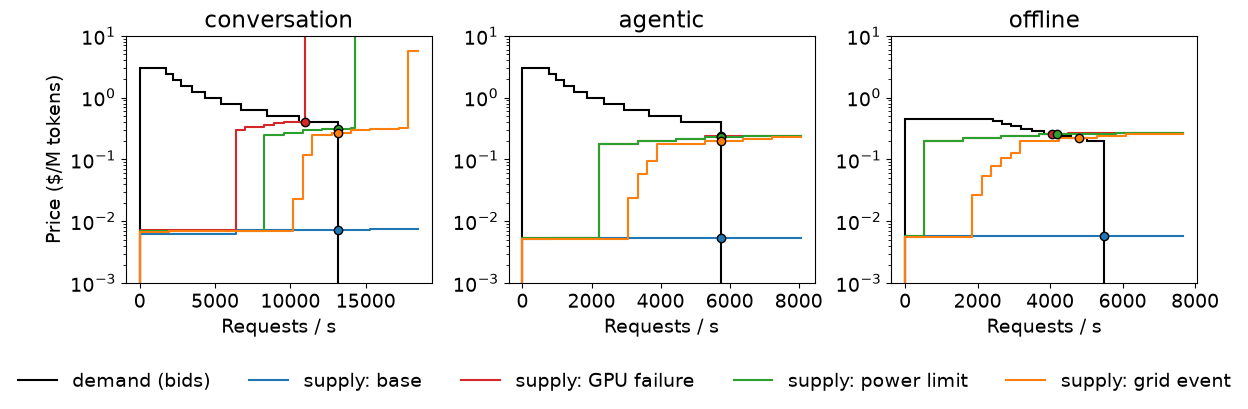

In [20]:
def trace_supply(kw, k, r, t, served):
    price = lambda res: per_Mtok(res, k, r, 0)
    Q = np.unique(np.r_[np.linspace(1, 1.4 * D_REQ[r, k, t], 30), max(served, 1.0)])
    q_ok, p_ok = [], []
    for q in Q:
        res = clear_market(**kw, hours=[t], fix=(k, r, q))
        if res is None:
            break
        q_ok.append(q); p_ok.append(price(res))

    if len(q_ok) < len(Q):                   # find the capacity limit by bisection
        lo, hi = (q_ok[-1] if q_ok else 0.0), q
        p_lo = p_ok[-1] if p_ok else np.nan
        for _ in range(8):
            mid = (lo + hi) / 2
            res = clear_market(**kw, hours=[t], fix=(k, r, mid))
            if res is None:
                hi = mid
            else:
                lo, p_lo = mid, price(res)
        q_ok += [lo, lo]; p_ok += [p_lo, 10]  # vertical at capacity
    return np.array([0, 0] + q_ok), np.array([1e-3, p_ok[0]] + p_ok)

# fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
# for k, c in enumerate(CLASSES):
#     q = SEG_SHARE[k] * D_REQ[REGION, k, TPK]
#     order = np.argsort(-PRICE[k]); order = order[q[order] > 0]
#     edges = np.r_[0, np.cumsum(q[order])]
#     ax[k].stairs(PRICE[k, order], edges, baseline=1e-3, color='k', lw=1.5, label='demand (bids)')
#     for name, kw in EVENTS.items():
#         served = RES[name]['served'][k, REGION, TPK]
#         Qs, Ps = trace_supply(kw, k, REGION, TPK, served)
#         ax[k].plot(Qs, Ps, drawstyle='steps-post', c=COLOR[name], label=f'supply: {name}')
#         ax[k].plot(served, per_Mtok(RES[name], k, REGION, TPK), 'o', c=COLOR[name], mec='k', ms=6, zorder=5)
#     ax[k].set(yscale='log', ylim=(1e-3, 10), xlabel='Requests / s', title=c)
# ax[0].set_ylabel('Price ($/M tokens)')
# ax[0].legend(fontsize=7, loc='lower left')
# plt.tight_layout(); plt.show()

with plt.rc_context({'font.size': 14}):
    fig, ax = plt.subplots(1, 3, figsize=(12, 4.2))
    for k, c in enumerate(CLASSES):
        q = SEG_SHARE[k] * D_REQ[REGION, k, TPK]
        order = np.argsort(-PRICE[k]); order = order[q[order] > 0]
        edges = np.r_[0, np.cumsum(q[order])]
        ax[k].stairs(PRICE[k, order], edges, baseline=1e-3, color='k', lw=1.5, label='demand (bids)')
        for name, kw in EVENTS.items():
            served = RES[name]['served'][k, REGION, TPK]
            Qs, Ps = trace_supply(kw, k, REGION, TPK, served)
            ax[k].plot(Qs, Ps, drawstyle='steps-post', c=COLOR[name], label=f'supply: {name}')
            ax[k].plot(served, per_Mtok(RES[name], k, REGION, TPK), 'o', c=COLOR[name], mec='k', ms=6, zorder=5)
        ax[k].set(yscale='log', ylim=(1e-3, 10), xlabel='Requests / s', title=c)
    ax[0].set_ylabel('Price ($/M tokens)')

    handles, labels = ax[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(handles), frameon=False)
    plt.tight_layout(rect=(0, 0.12, 1, 1))
    plt.show()

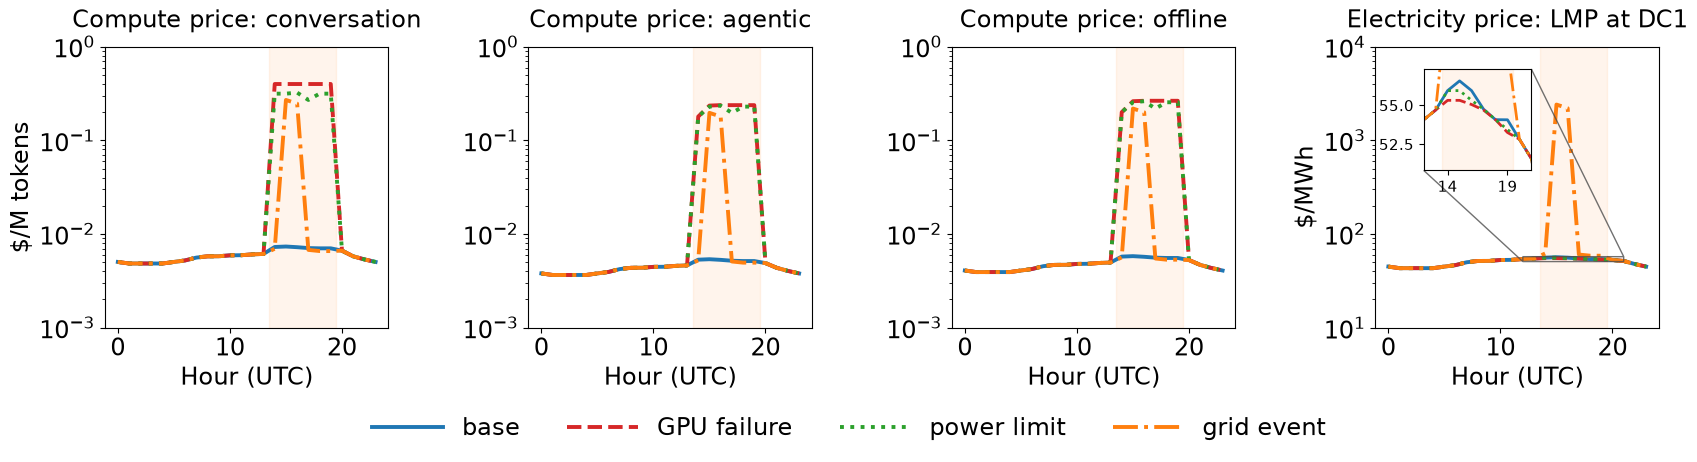

In [21]:
hours = np.arange(T)
LS = dict(zip(EVENTS, ['-', '--', ':', '-.']))
TITLE_KW = dict(pad=14, fontsize=17)
lmp = {name: RES[name]['nu'][:, SBUS[DC1]] for name in EVENTS}

# Inset window: event hours +/- 2, y-range of the events that keep the LMP near base
ZX = (EVENT[0] - 2, EVENT[-1] + 2)
near = np.concatenate([lmp[n][ZX[0]:ZX[1] + 1] for n in EVENTS if n != 'grid event'])
margin = 0.15 * (near.max() - near.min())
ZY = (near.min() - margin, near.max() + margin)

with plt.rc_context({'font.size': 17}):
    fig, ax = plt.subplots(1, 4, figsize=(17, 4.8))
    for a in ax:
        a.axvspan(EVENT[0] - 0.5, EVENT[-1] + 0.5, color='C1', alpha=0.08)

    # Panels 1-3: compute price in region 1
    for k, c in enumerate(CLASSES):
        for name in EVENTS:
            ax[k].plot(hours, [per_Mtok(RES[name], k, REGION, t) for t in hours],
                       c=COLOR[name], ls=LS[name], lw=2.8, label=name)
        ax[k].set(yscale='log', ylim=(1e-3, 1), xlabel='Hour (UTC)')
        ax[k].set_title(f'Compute price: {c}', **TITLE_KW)
    ax[0].set_ylabel('$/M tokens')

    # Panel 4: energy LMP at the DC1 bus
    for name in EVENTS:
        ax[3].plot(hours, lmp[name], c=COLOR[name], ls=LS[name], lw=2.8)
    ax[3].set(yscale='log', ylim=(10, 1e4), xlabel='Hour (UTC)', ylabel='$/MWh')
    ax[3].set_title('Electricity price: LMP at DC1', **TITLE_KW)

    # Inset: zoom into the event window on a linear scale
    axins = ax[3].inset_axes([0.17, 0.56, 0.38, 0.36])
    axins.axvspan(EVENT[0] - 0.5, EVENT[-1] + 0.5, color='C1', alpha=0.08)
    for name in EVENTS:
        axins.plot(hours, lmp[name], c=COLOR[name], ls=LS[name], lw=2)
    axins.set(xlim=ZX, ylim=ZY)
    axins.set_xticks([EVENT[0], EVENT[-1]])
    axins.tick_params(labelsize=11)
    ax[3].indicate_inset_zoom(axins, edgecolor='0.3', alpha=0.8)

    handles, labels = ax[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(handles), frameon=False, handlelength=3)
    plt.tight_layout(rect=(0, 0.1, 1, 1), w_pad=2.5)
    plt.show()

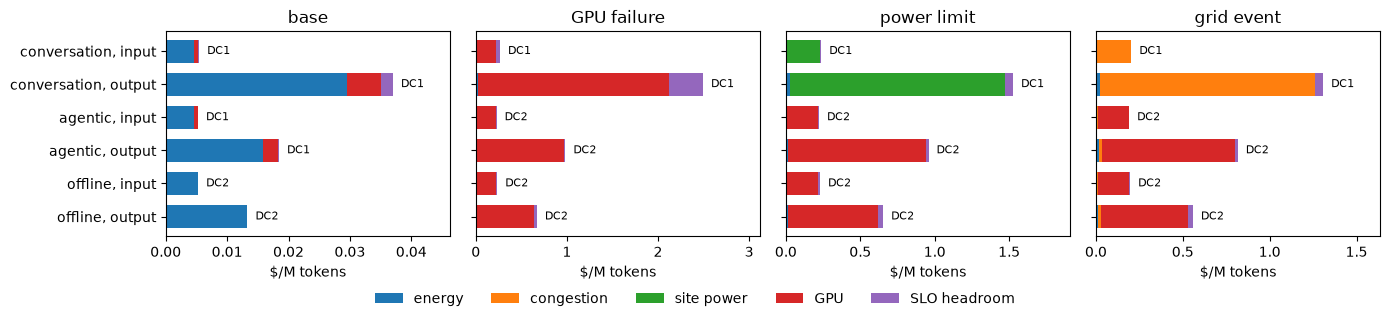

In [22]:
COLORS = {'energy': 'C0', 'congestion': 'C1', 'site power': 'C2', 'GPU': 'C3', 'SLO headroom': 'C4'}
fig, ax = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for j, name in enumerate(EVENTS):
    tab = DECOMP[name][DECOMP[name].region == REGION].copy()
    tab.index = tab.cls + ', ' + tab.part
    tab[COMPS].fillna(0).plot.barh(stacked=True, ax=ax[j], width=0.7, legend=False,
                                   color=[COLORS[x] for x in COMPS])
    for y, (total, site) in enumerate(zip(tab[COMPS].sum(axis=1), tab.site)):
        ax[j].text(total, y, '  curtailed' if site < 0 else f'  DC{site}', va='center', fontsize=8)
    ax[j].margins(x=0.25)
    ax[j].set(title=name, xlabel='$/M tokens')
ax[0].invert_yaxis()
fig.legend(*ax[0].get_legend_handles_labels(), loc='lower center', ncol=5,
           frameon=False, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

We relax the conversation ITL target and RTT budget one at a time and record its price and served share at the peak hour.

C:\Users\16467\AppData\Local\Temp\ipykernel_32256\3652244664.py:52: UserWarning: The problem has an expression with dimension greater than 2. Defaulting to the SCIPY backend for canonicalization.
  prob.solve(solver=cp.HIGHS)


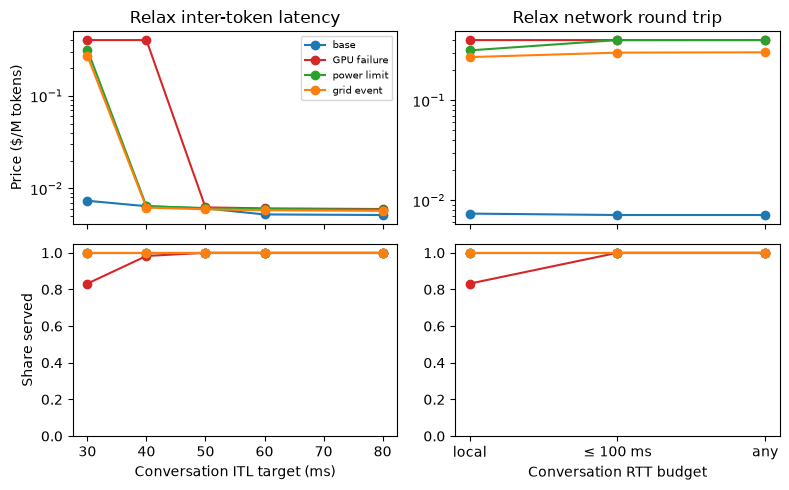

In [23]:
ITL_GRID = [30, 40, 50, 60, 80]              # ms
RTT_GRID = [0.05, 0.10, np.inf]              # s
RTT_LABELS = ['local', '≤ 100 ms', 'any']
k_conv = CLASSES.index('conversation')

def sweep_point(res, name, knob, x):
    return dict(event=name, knob=knob, x=x, price=per_Mtok(res, k_conv, REGION, 0),
                served=res['served'][k_conv, REGION, 0] / D_REQ[REGION, k_conv, TPK])

SWEEP = []
for name, kw in EVENTS.items():
    for L in ITL_GRID:
        res = clear_market(**kw, l_itl={**L_ITL, 'conversation': L}, hours=[TPK])
        SWEEP.append(sweep_point(res, name, 'ITL', L))
    for j, Rb in enumerate(RTT_GRID):
        res = clear_market(**kw, rtt_max={**RTT_MAX, 'conversation': Rb}, hours=[TPK])
        SWEEP.append(sweep_point(res, name, 'RTT', j))
SWEEP = pd.DataFrame(SWEEP)

fig, ax = plt.subplots(2, 2, figsize=(8, 5), sharex='col')
for name in EVENTS:
    for col, knob in enumerate(['ITL', 'RTT']):
        sw = SWEEP[(SWEEP.event == name) & (SWEEP.knob == knob)]
        ax[0, col].plot(sw.x, sw.price, 'o-', c=COLOR[name], label=name)
        ax[1, col].plot(sw.x, sw.served, 'o-', c=COLOR[name])
ax[0, 0].set(yscale='log', ylabel='Price ($/M tokens)', title='Relax inter-token latency')
ax[0, 1].set(yscale='log', title='Relax network round trip')
ax[1, 0].set(xlabel='Conversation ITL target (ms)', ylabel='Share served', ylim=(0, 1.05))
ax[1, 1].set(xlabel='Conversation RTT budget', ylim=(0, 1.05))
ax[1, 1].set_xticks(range(len(RTT_GRID)), RTT_LABELS)
ax[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

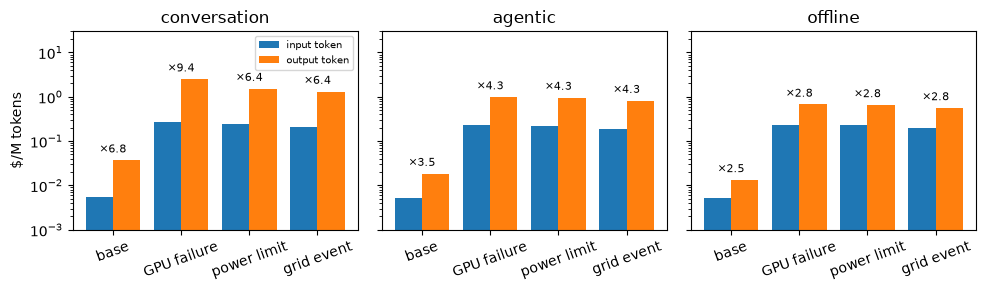

In [24]:
names = list(EVENTS); x = np.arange(len(names))
fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for k, c in enumerate(CLASSES):
    p_in, p_out = [], []
    for name in names:
        tab = DECOMP[name][(DECOMP[name].region == REGION) & (DECOMP[name].cls == c)].set_index('part')
        p_in.append(tab.loc['input', COMPS].sum(min_count=1))
        p_out.append(tab.loc['output', COMPS].sum(min_count=1))
    p_in, p_out = np.array(p_in, dtype=float), np.array(p_out, dtype=float)
    ax[k].bar(x - 0.2, p_in, 0.4, label='input token')
    ax[k].bar(x + 0.2, p_out, 0.4, label='output token')
    for j in range(len(names)):
        label = 'curtailed' if np.isnan(p_in[j]) else f'×{p_out[j] / p_in[j]:.1f}'
        ax[k].text(x[j], np.nanmax([p_out[j], 1e-3]) * 1.5, label, ha='center', fontsize=8)
    ax[k].set_xticks(x, names, rotation=20)
    ax[k].set(yscale='log', ylim=(1e-3, 30), title=c)
ax[0].set_ylabel('$/M tokens')
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [25]:
plt.savefig('fig_clearing.pdf', bbox_inches='tight')        # Fig. 2
plt.savefig('fig_price_day.pdf', bbox_inches='tight')       # Fig. 3
plt.savefig('fig_decomposition.pdf', bbox_inches='tight')   # Fig. 4
plt.savefig('fig_slo_sweep.pdf', bbox_inches='tight')
plt.savefig('fig_input_output.pdf', bbox_inches='tight')

<Figure size 640x480 with 0 Axes>